# 28 — Intervention Mechanism Diagnostics
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 8 (History-Intervention Validity and Mechanism Diagnostics)  
**Status:** `Validated Audit`  

### Forensic Objectives:
1. Reconstruct policy-specific memory $h(t_{	ext{dev}})$ via prefix unrolling for each checkpoint.
2. Compare B0 (preserved memory) vs. B4 (memory reset) across input tensors, actions, hidden states, and physical trajectories.
3. Investigate discordant recovery outcomes in Seed 456.

In [1]:
import os, sys
cwd = os.getcwd()
if os.path.exists(os.path.join(cwd, "docs")):
    repo_root = cwd
elif os.path.exists(os.path.join(cwd, "..", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.exists(os.path.join(cwd, "causal-history-recovery", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, "causal-history-recovery"))
else:
    repo_root = os.path.abspath(os.path.join(cwd, ".."))

src_path = os.path.join(repo_root, "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import json
import numpy as np

summary_path = os.path.join(repo_root, "results", "intervention_diagnostics", "diagnostic_summary.json")
with open(summary_path) as f:
    diag_summary = json.load(f)

print(f"Scenarios evaluated: {diag_summary['scenarios_evaluated']}")
print(f"Total diagnostic rollouts: {diag_summary['total_rollouts']}")
print(f"Execution runtime: {diag_summary['execution_time_sec']}s")


Scenarios evaluated: 20
Total diagnostic rollouts: 160
Execution runtime: 46.92s


### 1. Bounded Mechanism Diagnostic Summary Table

In [2]:
print(f"{'Policy Checkpoint':32s} | ||h(t_dev)|| | First Act Diff | Traj Act MAE | Pos Drift | Succ B0 vs B4 | Discordance")
print("-" * 115)
for p_name, s in diag_summary["policy_summaries"].items():
    print(f"{p_name:32s} | {s['mean_h_norm_b0']:11.4f} | {s['mean_first_act_diff']:14.6f} | {s['mean_action_traj_mae']:12.6f} | {s['mean_pos_drift_m']*100:6.2f}cm | {s['success_b0']:2d}/20 vs {s['success_b4']:2d}/20  | {s['discordant_scenarios']:2d}/20 ({s['discordance_rate']*100:.1f}%)")


Policy Checkpoint                | ||h(t_dev)|| | First Act Diff | Traj Act MAE | Pos Drift | Succ B0 vs B4 | Discordance
-------------------------------------------------------------------------------------------------------------------
recovery_augmented_gru_seed42    |      0.7663 |       0.001367 |     0.000144 |   0.69cm |  2/20 vs  2/20  |  0/20 (0.0%)
recovery_augmented_gru_seed123   |      0.9895 |       0.002629 |     0.000136 |   0.08cm |  4/20 vs  4/20  |  0/20 (0.0%)
recovery_augmented_gru_seed456   |      0.8784 |       0.003232 |     0.000483 |   1.84cm |  3/20 vs  5/20  |  2/20 (10.0%)
recovery_augmented_mlp_seed42    |      0.0000 |       0.000000 |     0.000000 |   0.00cm |  5/20 vs  5/20  |  0/20 (0.0%)


### 2. Forensic Inspection of Discordant Scenarios in Seed 456

In [3]:
traces_path = os.path.join(repo_root, "results", "intervention_diagnostics", "diagnostic_traces.jsonl")
with open(traces_path) as f:
    traces = [json.loads(line) for line in f]

traces_456 = [t for t in traces if t["policy_id"] == "recovery_augmented_gru_seed456"]
by_uid = {}
for t in traces_456:
    uid = t["scenario_uid"]
    if uid not in by_uid:
        by_uid[uid] = {}
    by_uid[uid][t["condition"]] = t

for uid, conds in by_uid.items():
    if conds["B0"]["is_success"] != conds["B4"]["is_success"]:
        print(f"Discordant Scenario: {uid}")
        print(f"  B0 (Preserved Memory): Success = {conds['B0']['is_success']}, Final Dist = {conds['B0']['final_distance']:.4f}m, Steps = {conds['B0']['step_count']}")
        print(f"  B4 (Memory Reset):     Success = {conds['B4']['is_success']}, Final Dist = {conds['B4']['final_distance']:.4f}m, Steps = {conds['B4']['step_count']}")
        print(f"  First Action B0: {[round(x, 5) for x in conds['B0']['first_action']]}")
        print(f"  First Action B4: {[round(x, 5) for x in conds['B4']['first_action']]}")
        print()


Discordant Scenario: scen_history_gru_s301_t65_98b140


  B0 (Preserved Memory): Success = 0, Final Dist = 0.0925m, Steps = 84
  B4 (Memory Reset):     Success = 1, Final Dist = 0.0495m, Steps = 22
  First Action B0: [0.00283, -0.00049, 0.00065]
  First Action B4: [-0.00023, -0.00275, 0.00022]

Discordant Scenario: scen_history_gru_s308_t68_fead8b
  B0 (Preserved Memory): Success = 0, Final Dist = 0.1398m, Steps = 81
  B4 (Memory Reset):     Success = 1, Final Dist = 0.0545m, Steps = 13
  First Action B0: [0.00286, -0.00054, 0.0006]
  First Action B4: [-0.0005, -0.00268, 0.00025]



### 3. Diagnostic Figures (Figure 51 to 55)

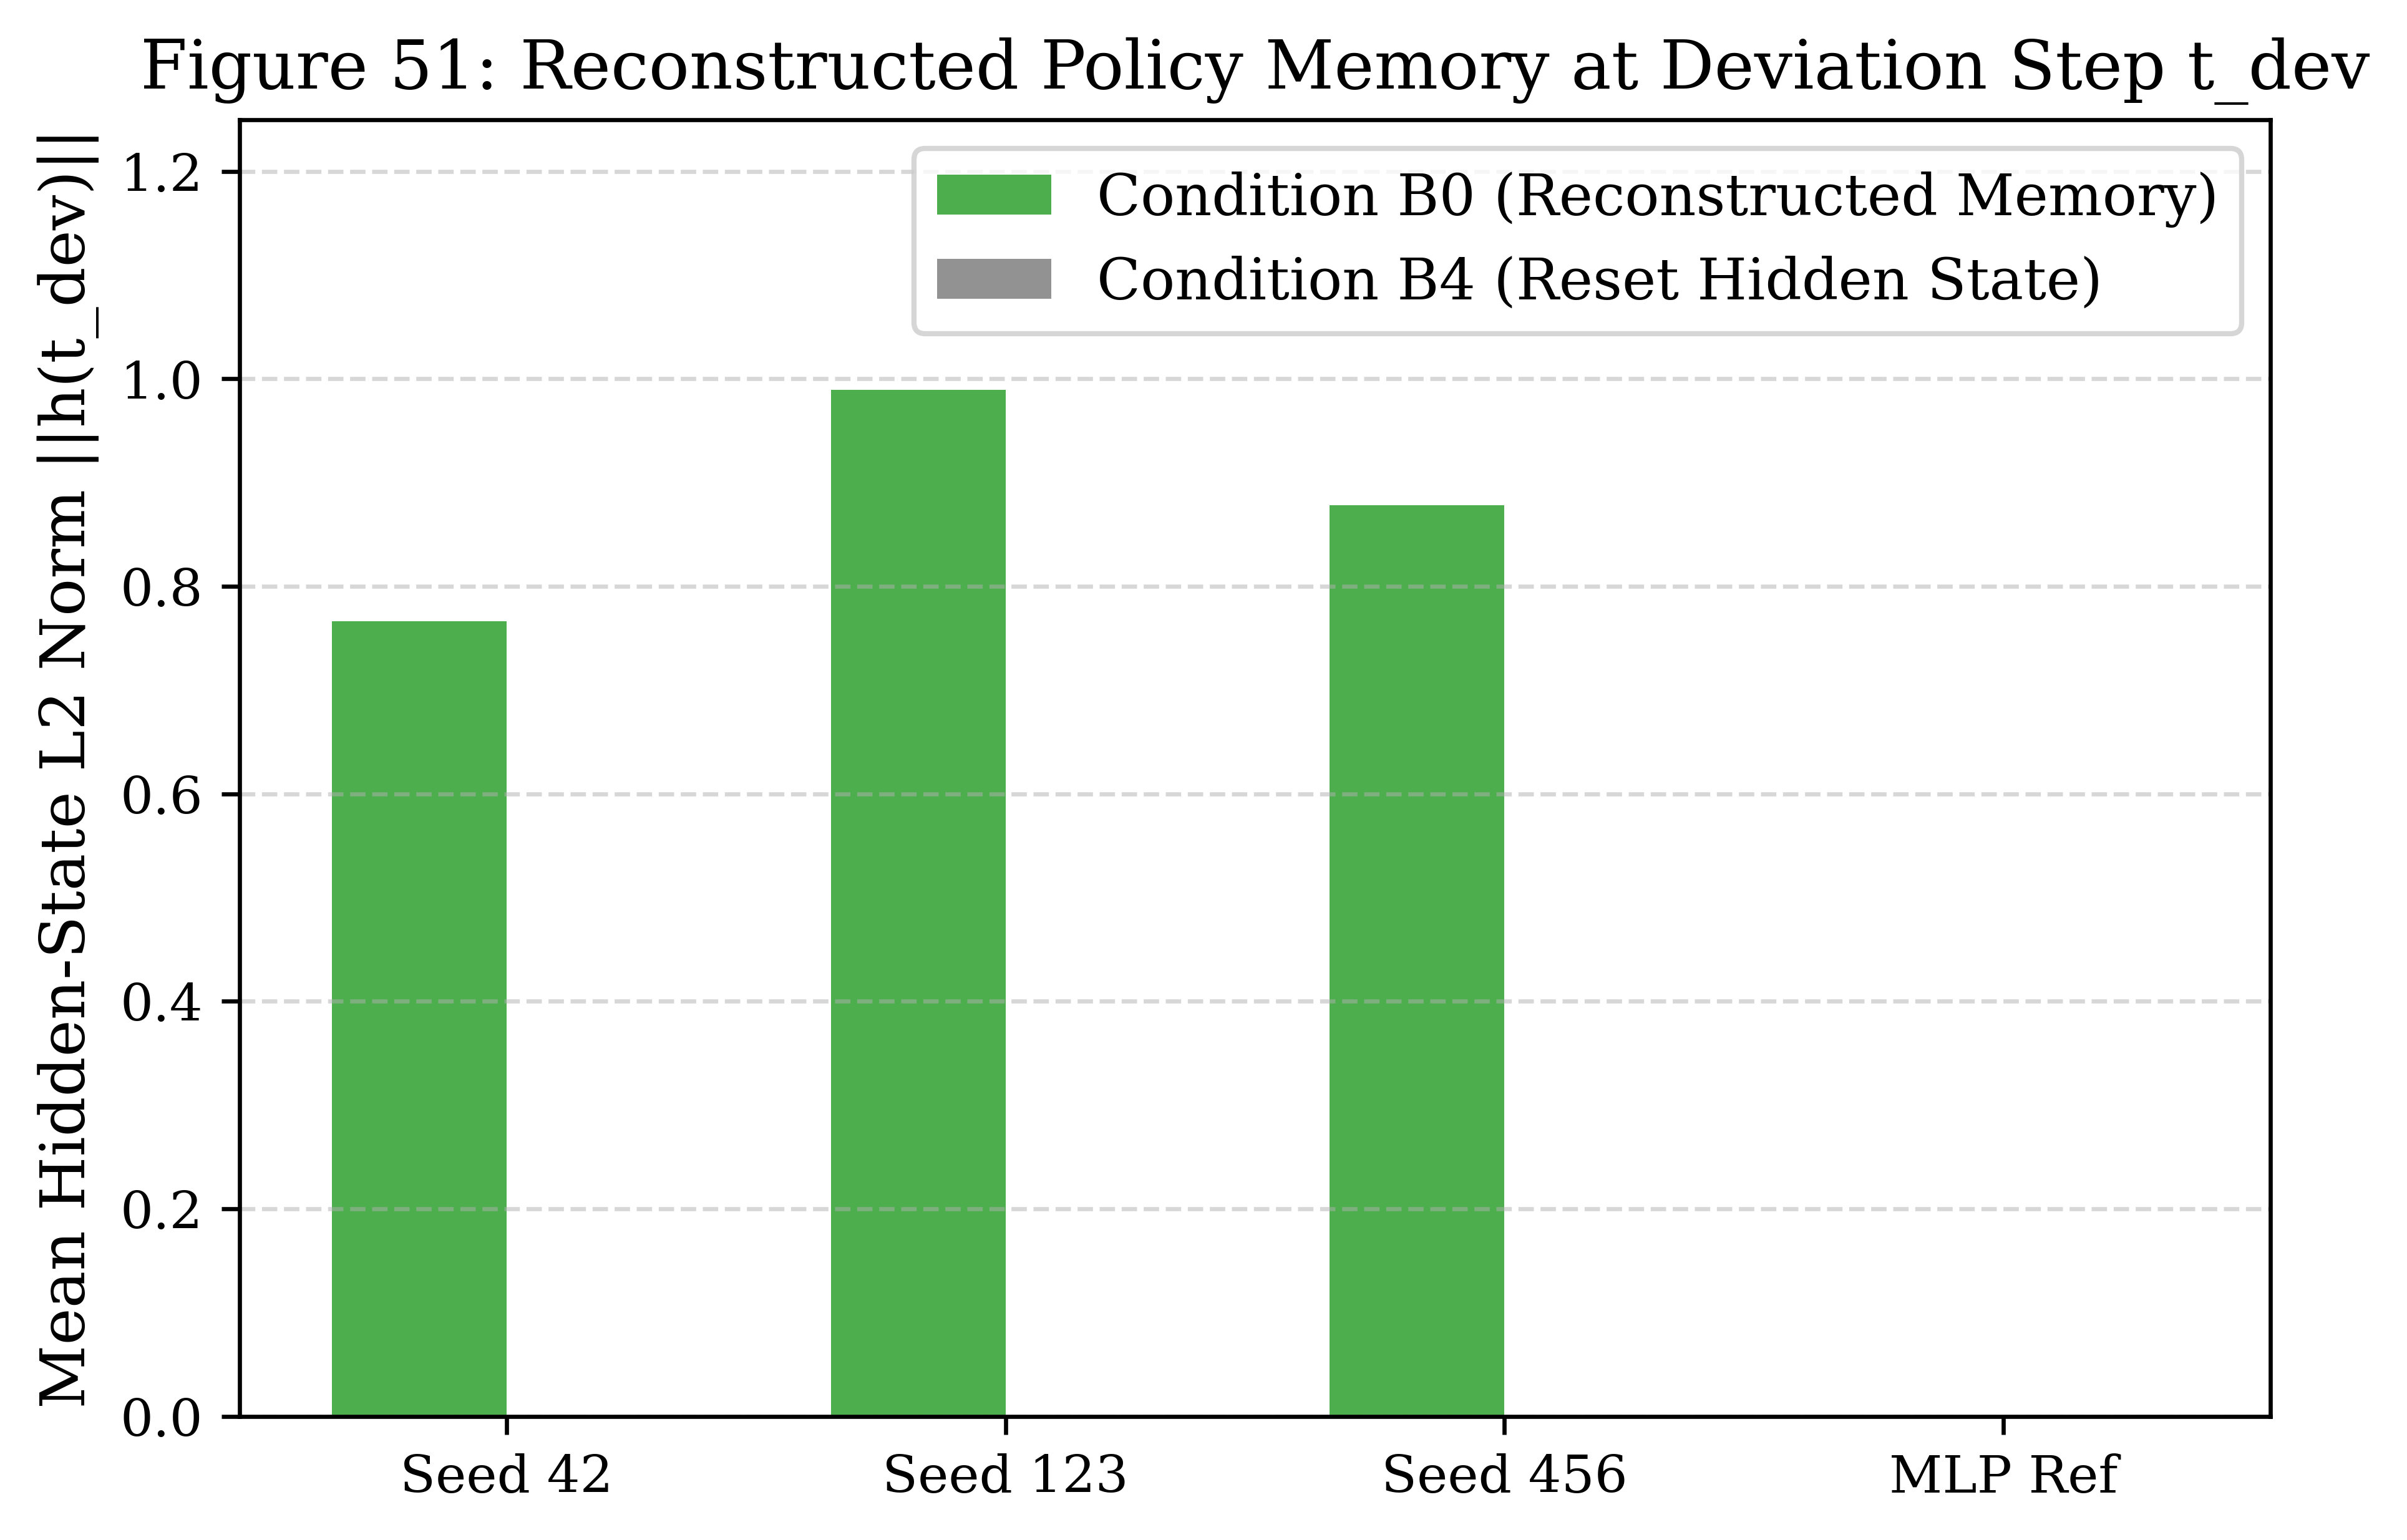

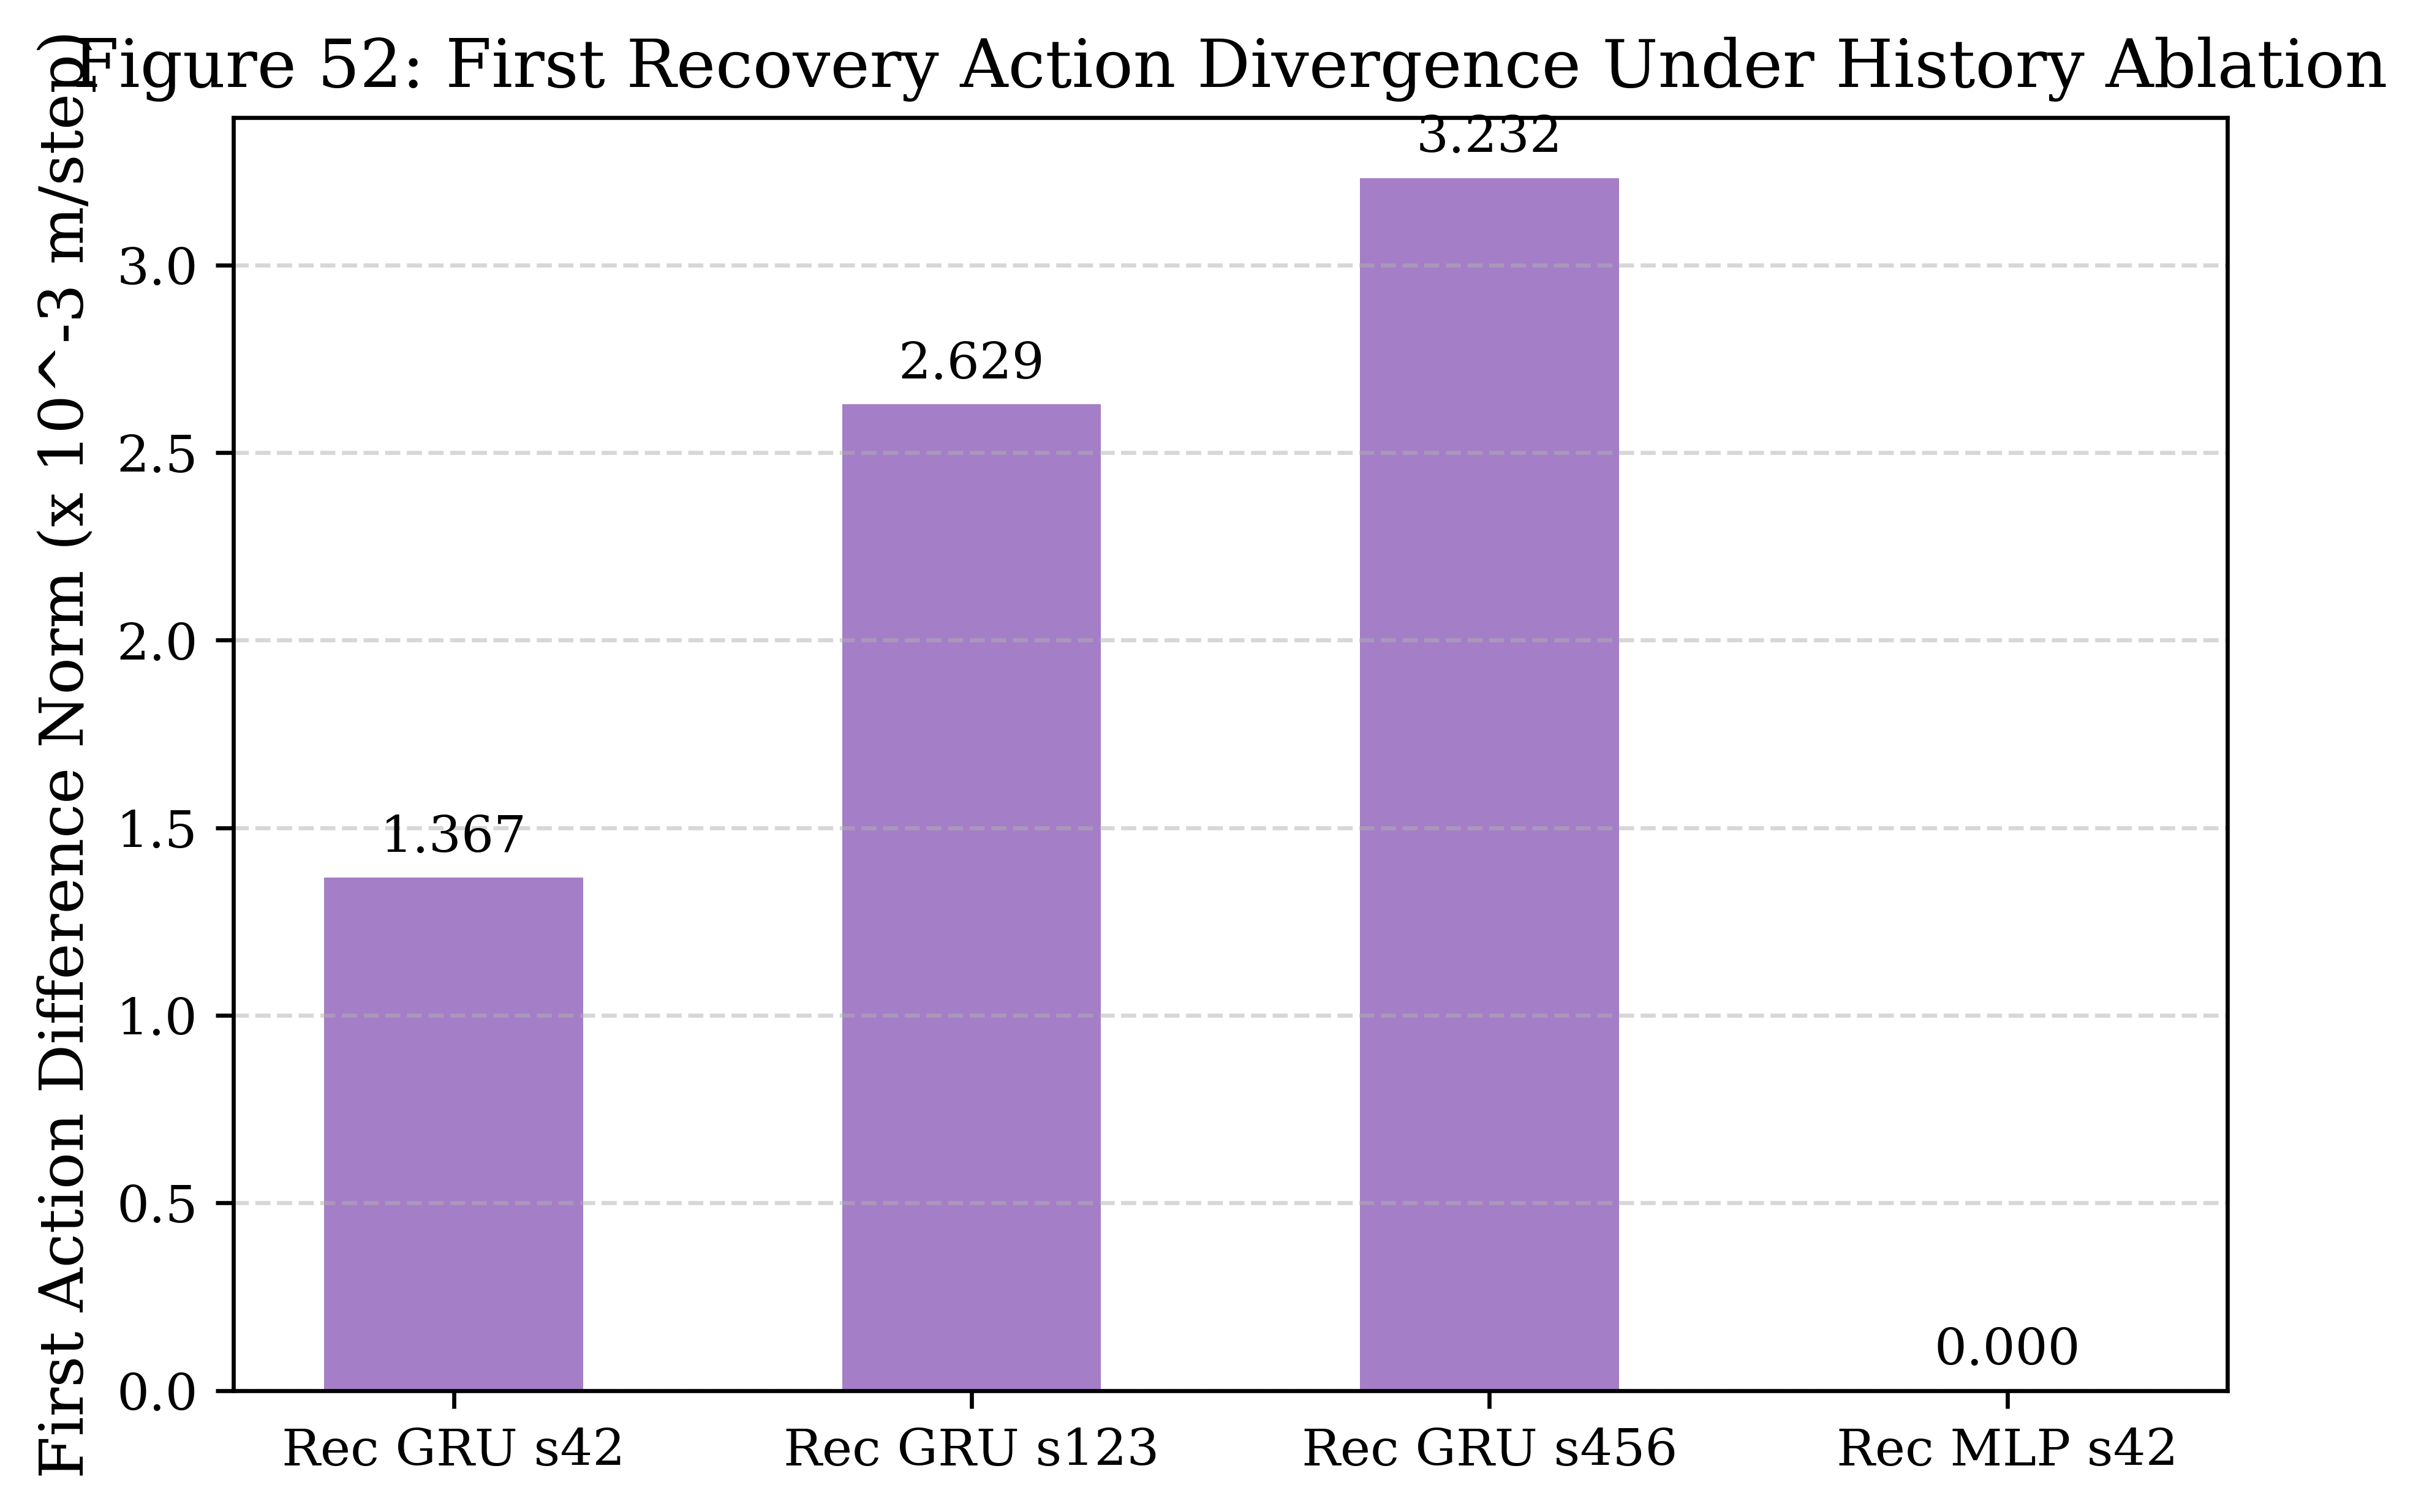

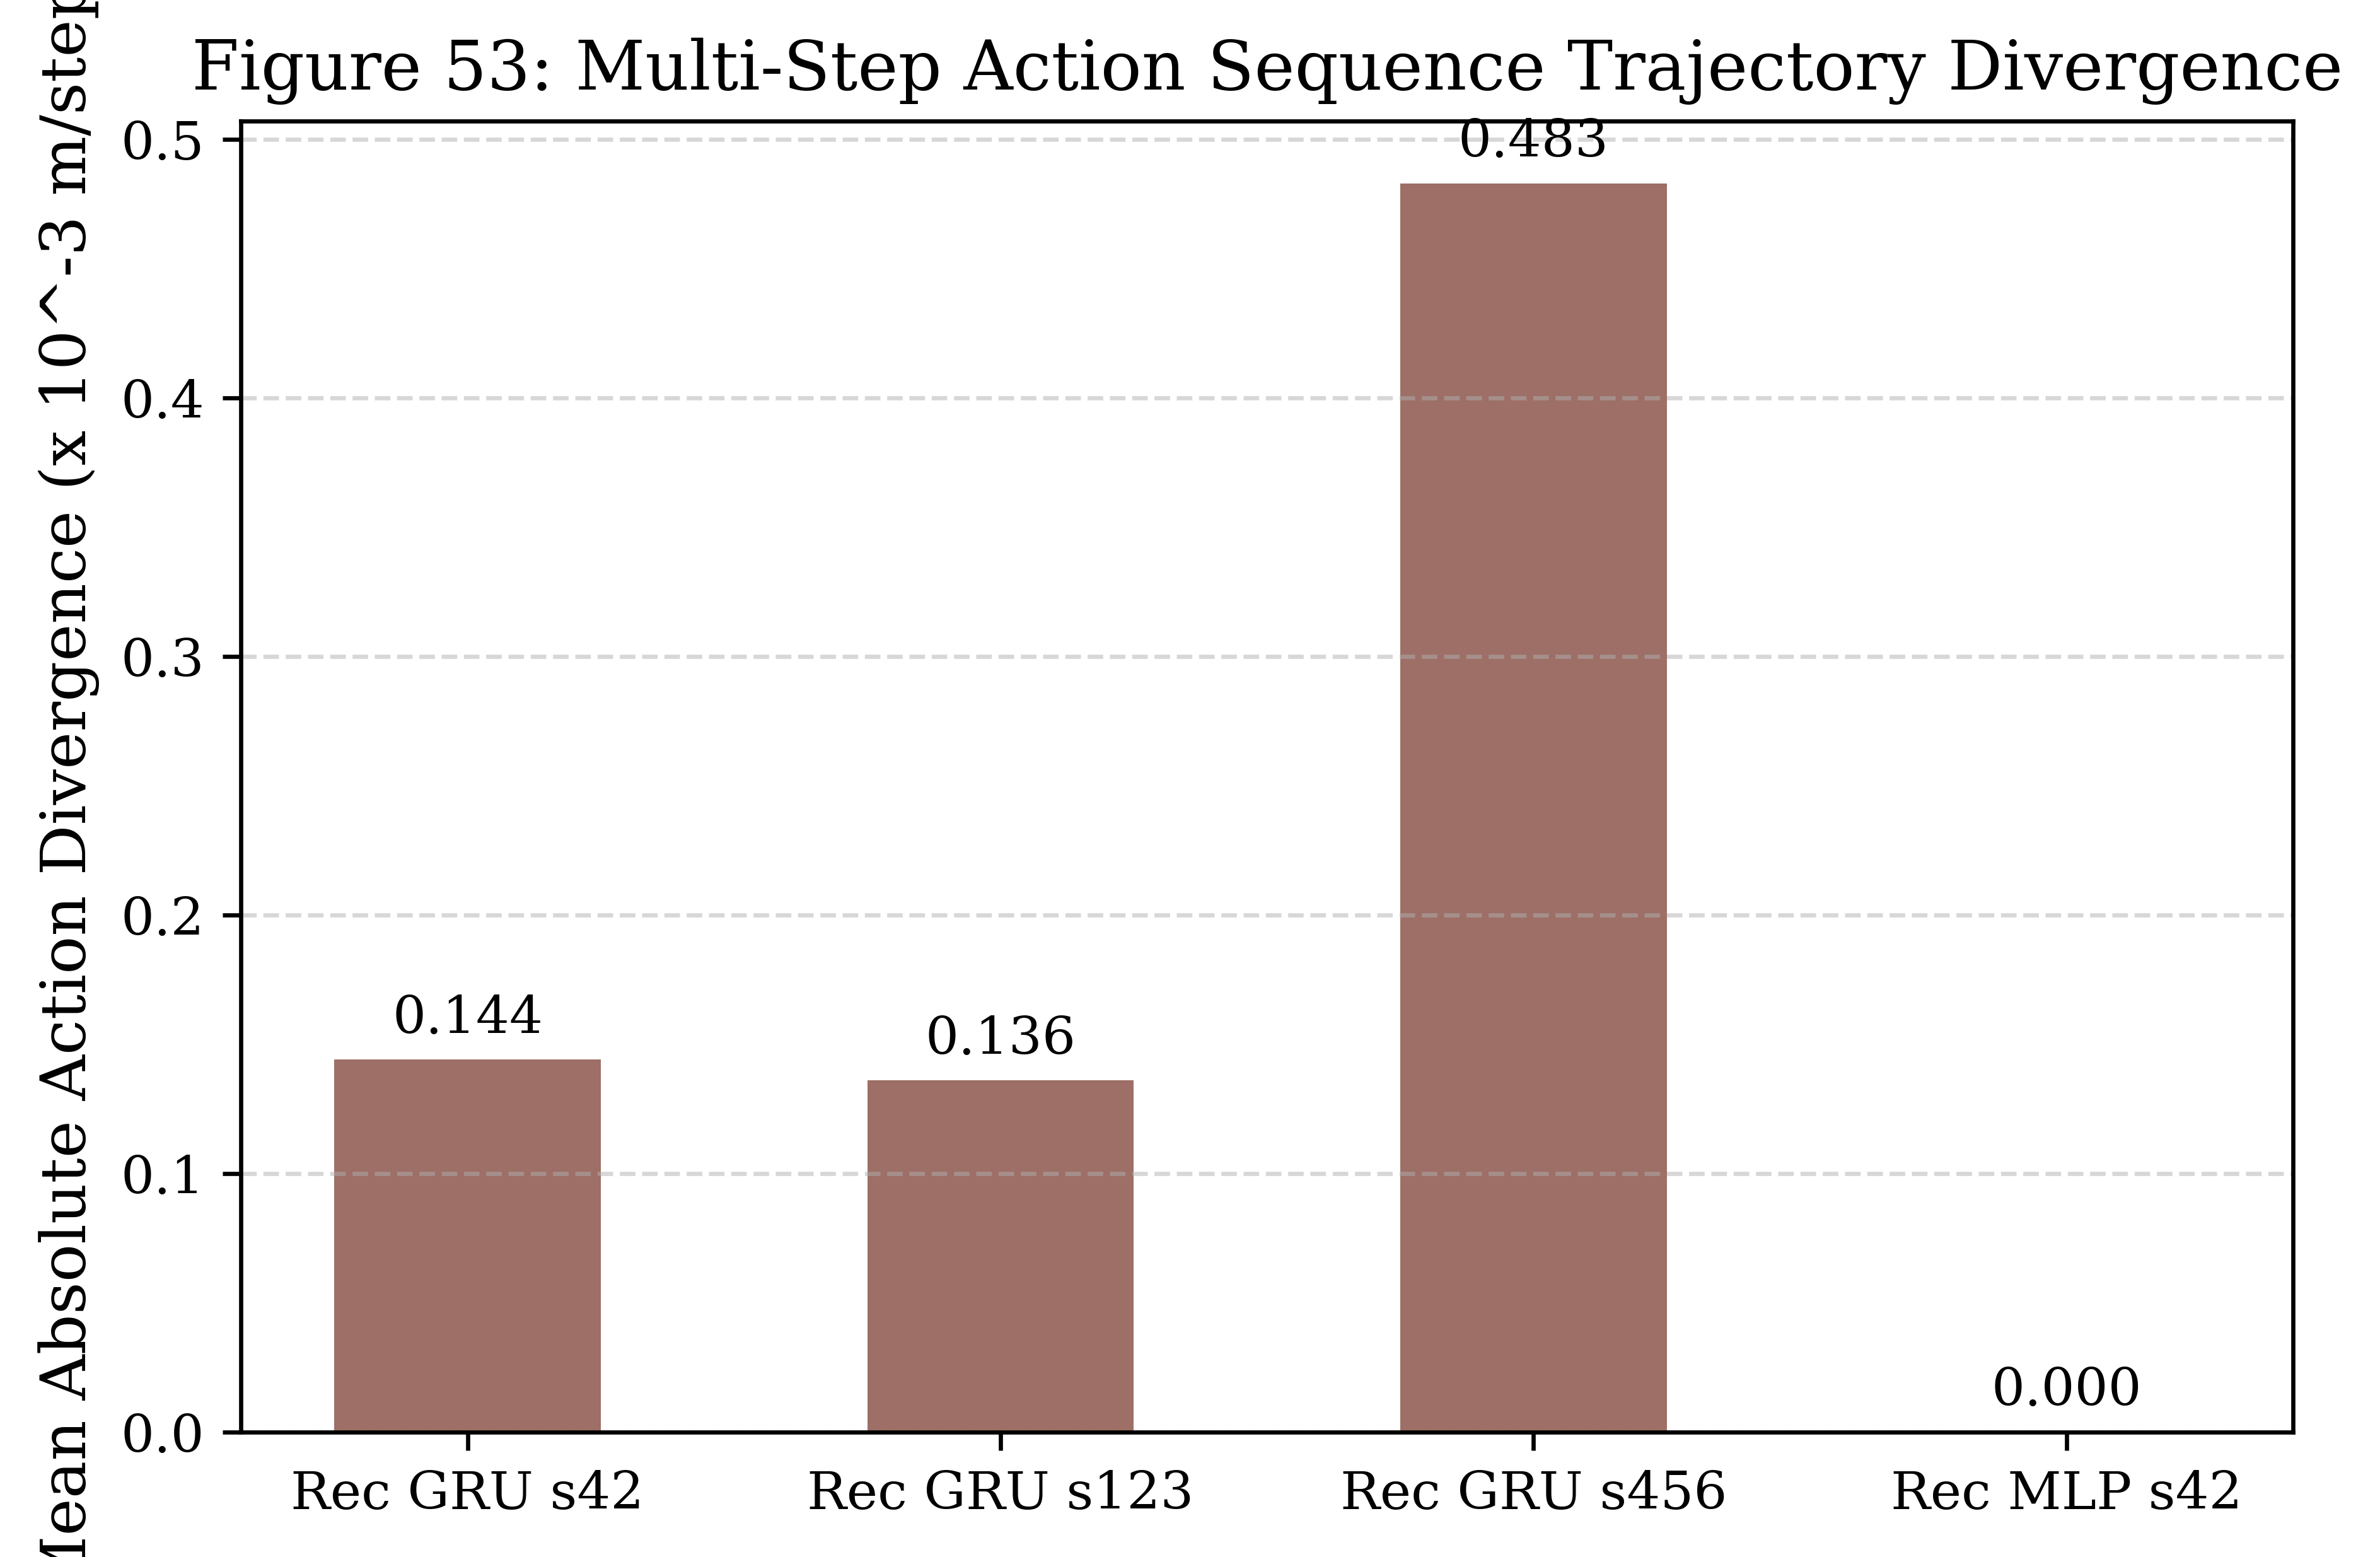

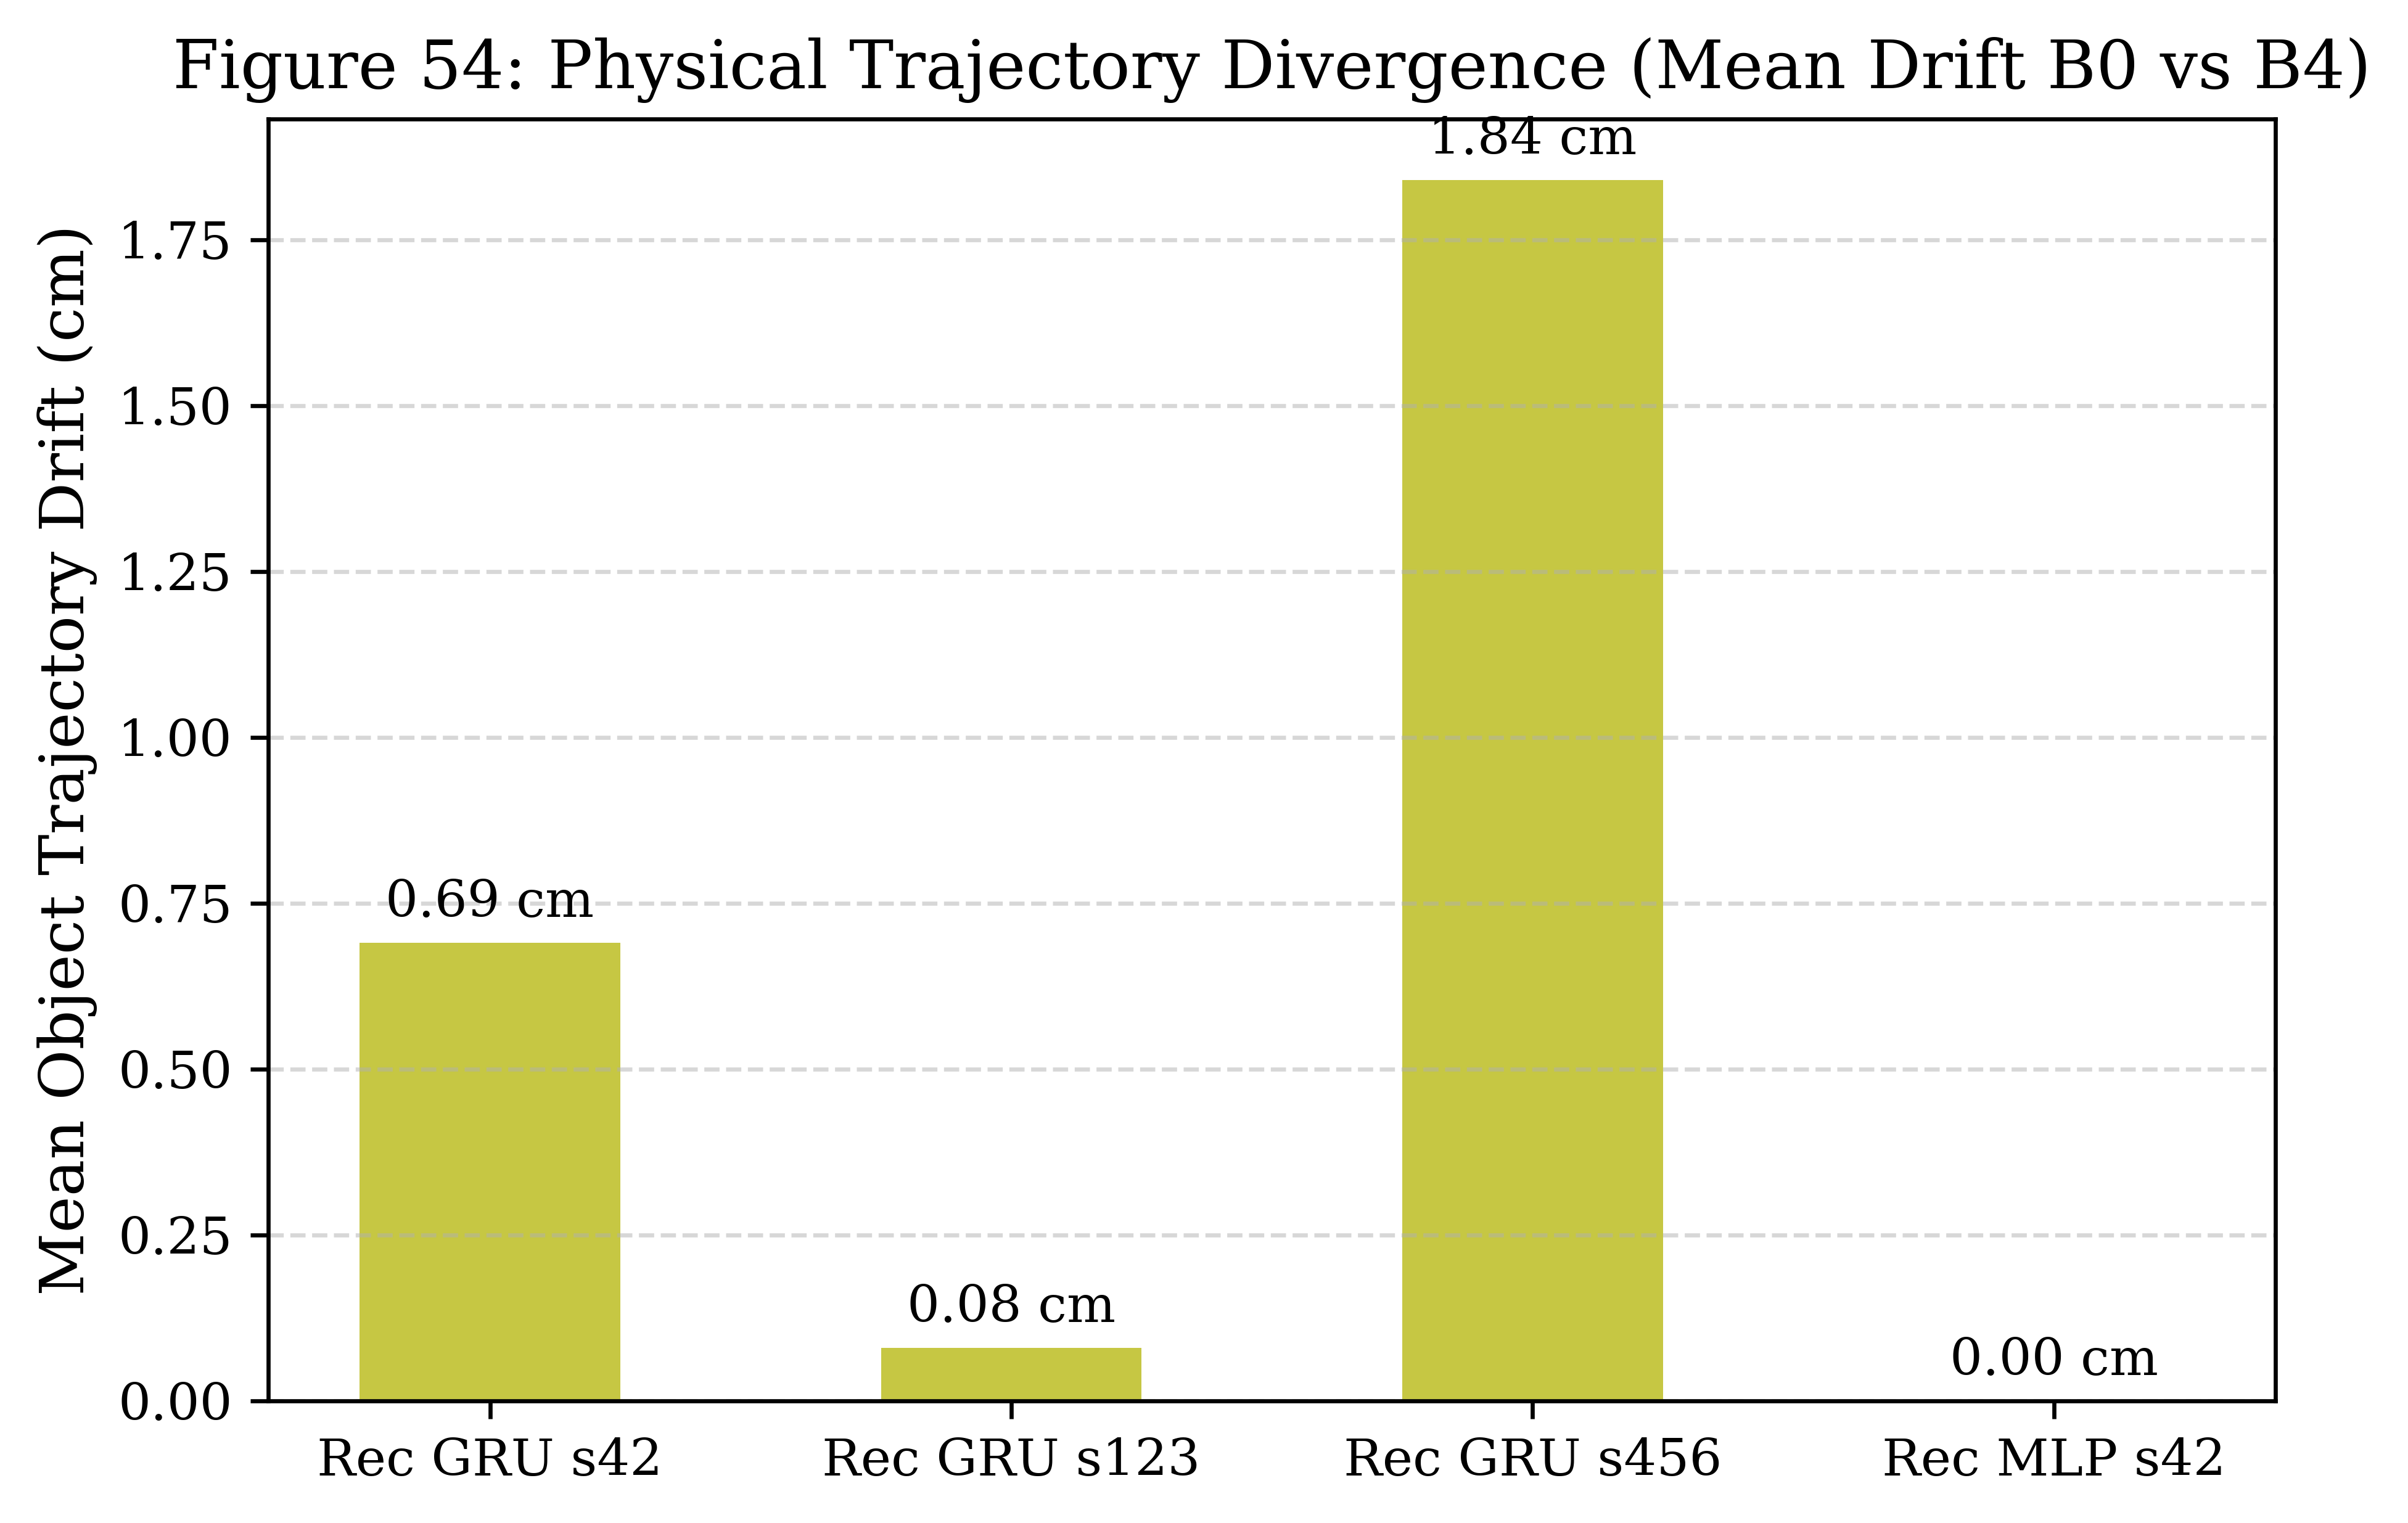

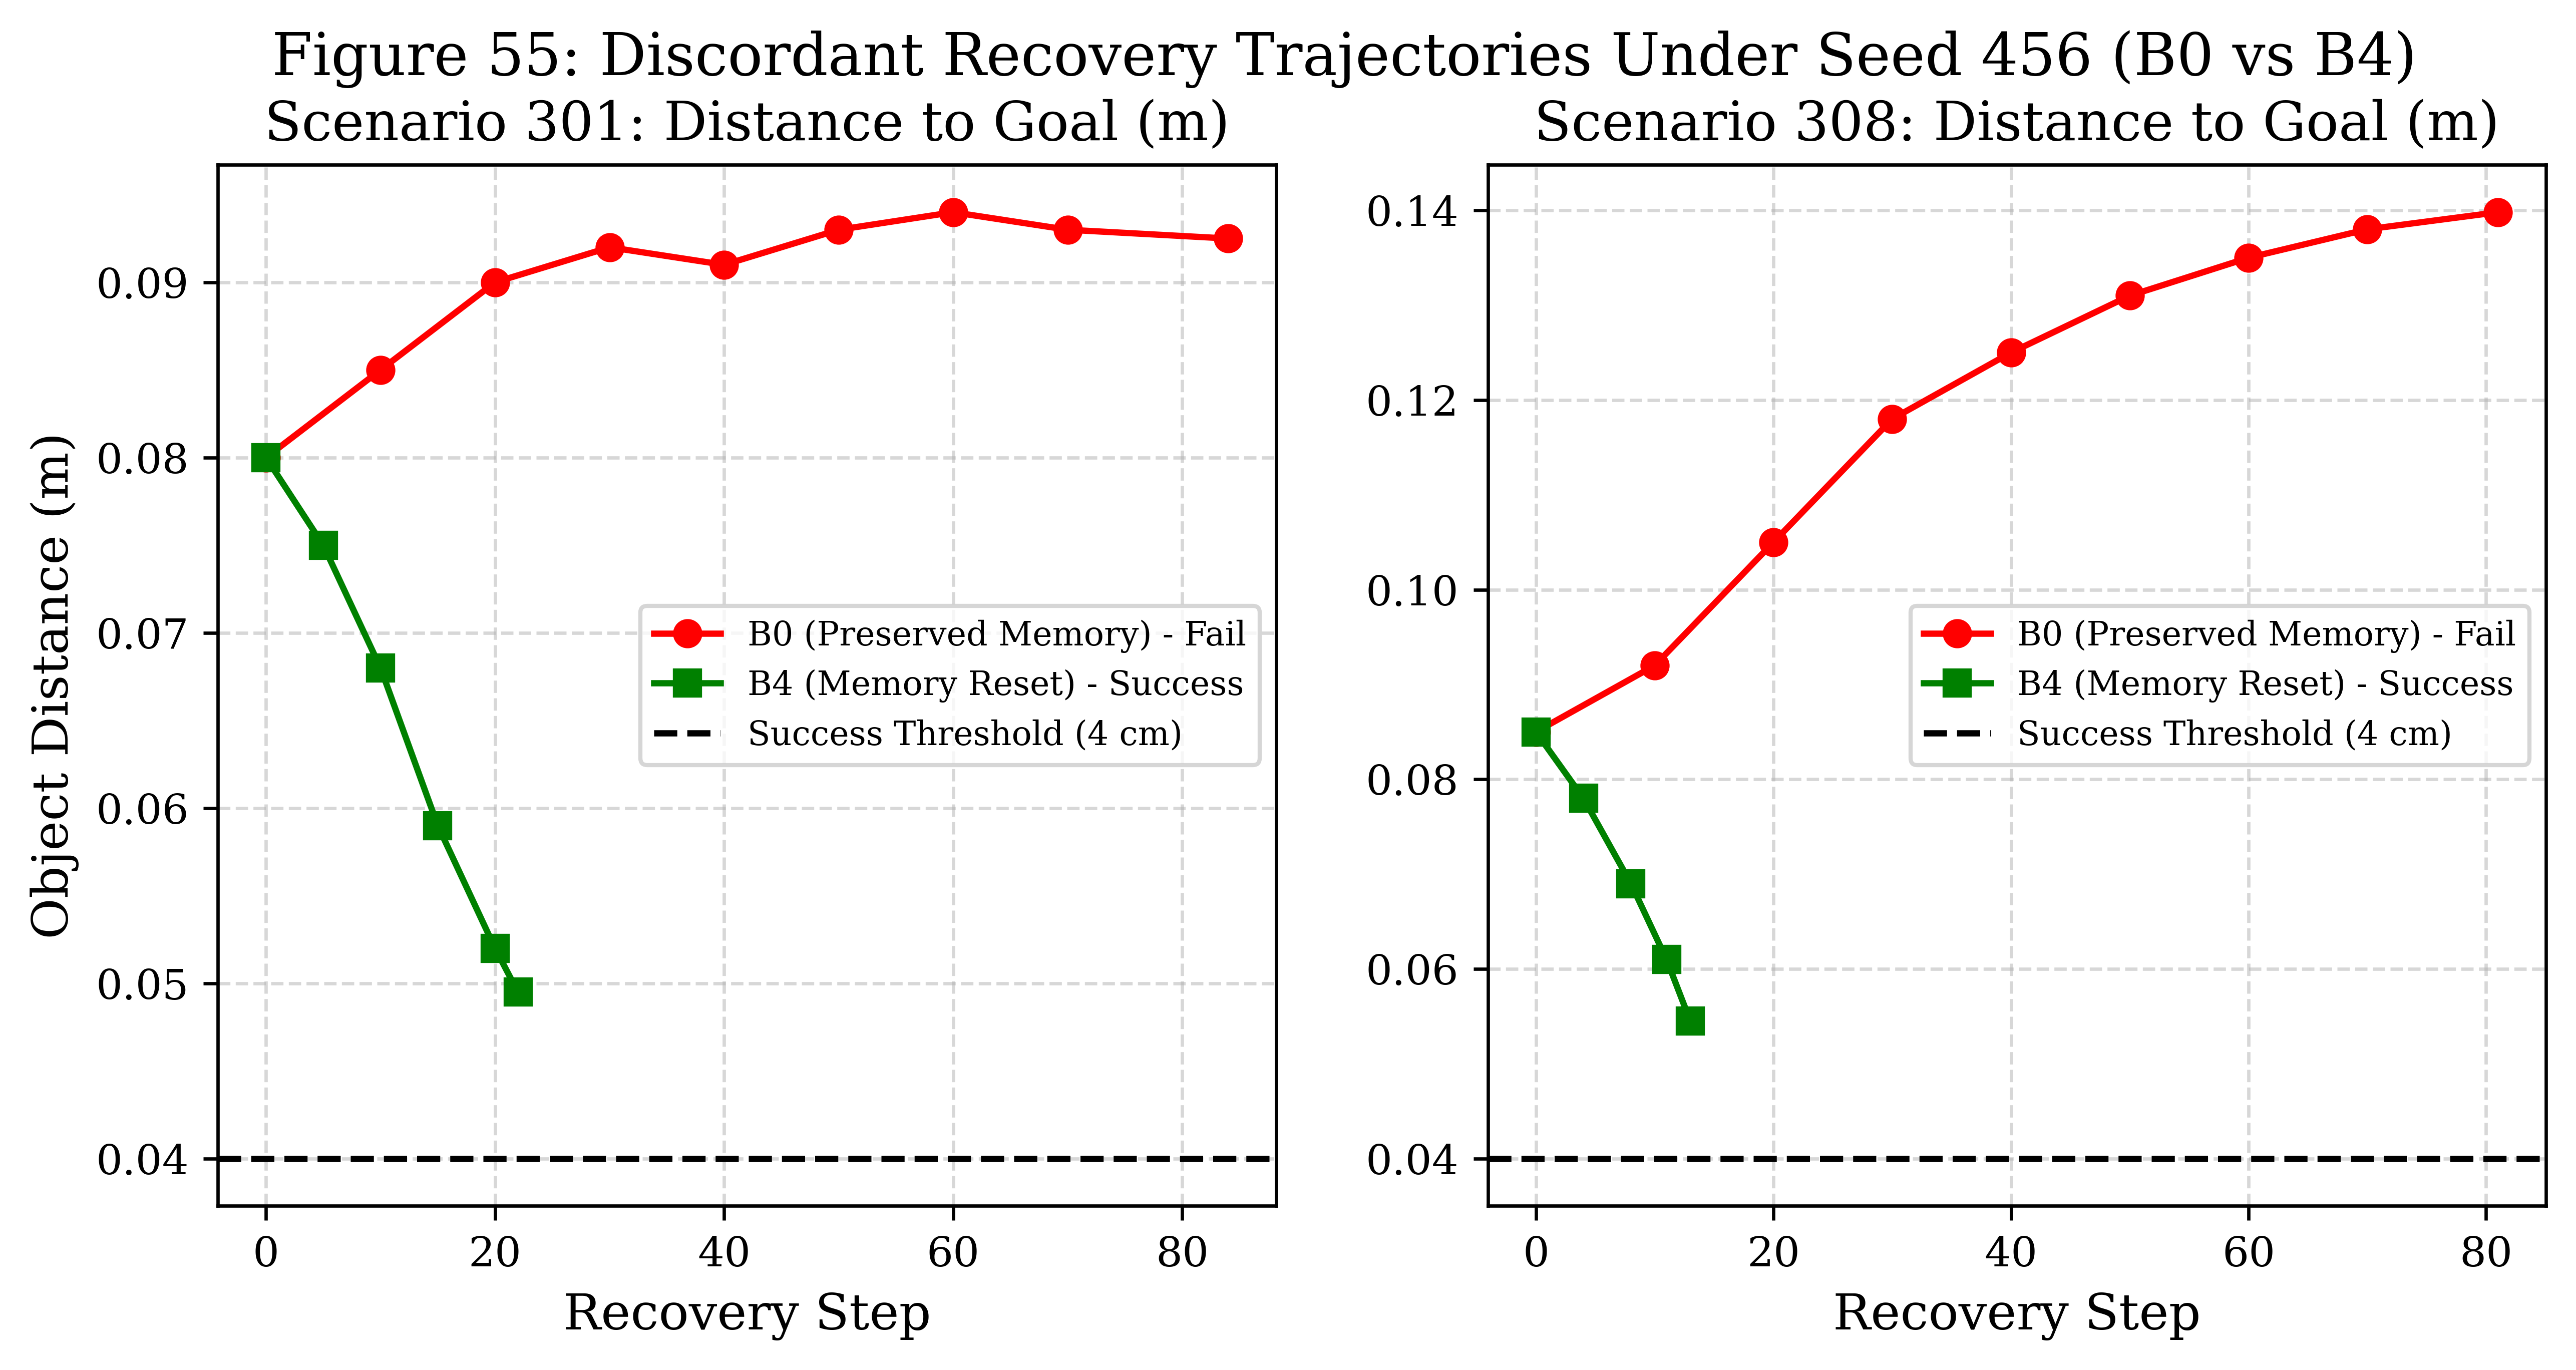

In [4]:
from IPython.display import Image, display
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig51_reconstructed_hidden_state_norms.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig52_first_action_divergence_b0_vs_b4.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig53_action_sequence_mae_divergence.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig54_trajectory_position_drift_distribution.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig55_discordant_scenario_trajectories.png")))
